In [286]:
import pandas as pd
import numpy as np
import sys
import os
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du

data_frame = pd.read_csv("../../data/raw/laboratory_events_codes_2.csv")

In [287]:
# Identify rows where 'value' is not "___" and 'valuenum' is NaN
mask_val = (data_frame['value'] != "___")
mask_valnum = (data_frame['valuenum'].isna())
data_frame[mask_val & mask_valnum]

,hadm_id,charttime,value,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
171,26913865.0,2189-07-02 10:20:00,NaN,NaN,NaN,NaN,NaN,NaN,EDTA Hold,Blood,EDTA Hold,BATCH_218907_Z1,OK,Normal range: 70-110
193,26913865.0,2189-07-02 10:20:00,NaN,NaN,NaN,NaN,NaN,NaN,Red Top Hold,Blood,Red Top Hold,BATCH_218907_J6,OK,NaN
330,23822395.0,2129-08-06 10:48:00,NOT INTUBATED.,NaN,NaN,NaN,NaN,NaN,Intubated,Blood,Blood Gas,BATCH_212908_B1,OK,NaN
335,23822395.0,2129-08-06 10:48:00,ART.,NaN,NaN,NaN,NaN,NaN,Specimen Type,Blood,Blood Gas,BATCH_212908_H8,OK,Normal range: 70-110
337,23822395.0,2129-08-06 18:54:00,NaN,NaN,NaN,NaN,NaN,NaN,Length of Urine Collection,Urine,Urine Test,BATCH_212908_N2,OK,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
978242,24169669.0,2128-02-25 06:36:00,NaN,NaN,sec,25.0,36.5,NaN,PTT,Blood,Coagulation and Hemostasis,BATCH_212802_P5,OK,NaN
978247,24169669.0,2128-02-25 09:58:00,VEN.,NaN,NaN,NaN,NaN,NaN,Specimen Type,Blood,Blood Gas,BATCH_212802_B5,WARN,Normal range: 3-5
978290,24169669.0,2128-02-26 20:00:00,ART.,NaN,NaN,NaN,NaN,NaN,Specimen Type,Blood,Blood Gas,BATCH_212802_N2,OK,Normal range: 70-110
978347,21557581.0,2145-07-26 16:14:00,NaN,NaN,NaN,NaN,NaN,NaN,Length of Urine Collection,Urine,Urine Test,BATCH_214507_F5,OK,NaN


In [288]:
data_frame=data_frame.drop(columns='value')
data_frame

,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,NaN,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3,OK,NaN
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,NaN,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7,OK,NaN
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,abnormal,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4,OK,NaN
3,29654838.0,2188-01-05 06:56:00,1.20,NaN,0.9,1.10,abnormal,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7,OK,NaN
4,29654838.0,2188-01-05 06:56:00,12.80,sec,9.4,12.50,abnormal,PT,Blood,Coagulation and Hemostasis,BATCH_218801_B1,WARN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
978498,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,NaN,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1,OK,NaN
978499,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,NaN,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5,OK,NaN
978500,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,abnormal,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7,OK,NaN
978501,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,NaN,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6,OK,NaN


In [289]:
grouped = data_frame.groupby('examination_group')['label'].unique()
examination_values_list = grouped.to_dict()
examination_values_list.keys()
grouped

examination_group
ADP                                                                            [ADP]
ANCA Titer                                                              [ANCA Titer]
ARCH-1                                                                      [ARCH-1]
Absolute CD3 Count                                              [Absolute CD3 Count]
Absolute CD4 Count                                              [Absolute CD4 Count]
                                                         ...                        
Urine Test                         [Length of Urine Collection, Urine tube, held,...
Virology                                                [Cytomegalovirus Viral Load]
Vitamin and Nutritional Studies    [Vitamin B12, Ferritin, Folate, Iron, Iron Bin...
Voided Specimen                                                    [Voided Specimen]
proBNP, Pleural                                                    [proBNP, Pleural]
Name: label, Length: 202, dtype: object

Modifico la colonna "flag": i valori NaN diventano 0 e il valore "abnormal" diventa 1

In [290]:
data_frame["flag"] = data_frame["flag"].replace(np.nan, 0)
data_frame["flag"] = data_frame["flag"].replace("abnormal", 1)
data_frame


/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_8076/2529097614.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_frame["flag"] = data_frame["flag"].replace("abnormal", 1)


,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3,OK,NaN
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7,OK,NaN
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4,OK,NaN
3,29654838.0,2188-01-05 06:56:00,1.20,NaN,0.9,1.10,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7,OK,NaN
4,29654838.0,2188-01-05 06:56:00,12.80,sec,9.4,12.50,1,PT,Blood,Coagulation and Hemostasis,BATCH_218801_B1,WARN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
978498,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1,OK,NaN
978499,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5,OK,NaN
978500,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7,OK,NaN
978501,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6,OK,NaN


In [291]:
def get_none_percentage_per_cols(data_frame):
    res = []
    cols = du.get_cols(data_frame)
    rows = data_frame.shape[0]
    for col in cols:
        not_none = (data_frame[col].count())
        none_percentage = ((rows - not_none)/rows)*100
        res.append((col, none_percentage))
    return res
# Get the percentage of None values for each columns
none_percentage_per_cols = []

print("PERCENTAGE OF NONE PER COLUMN")
for col, percentage in sorted(get_none_percentage_per_cols(data_frame), key=lambda tup: tup[1], reverse=True):
    print(f"{col}: {percentage:.2f}%")

PERCENTAGE OF NONE PER COLUMN
ref_range: 85.06%
ref_range_lower: 11.54%
ref_range_upper: 11.54%
valueuom: 9.60%
valuenum: 7.27%
hadm_id: 0.00%
charttime: 0.00%
flag: 0.00%
label: 0.00%
fluid: 0.00%
examination_group: 0.00%
analysis_batch_id: 0.00%
qc_flag: 0.00%


In [292]:
# Merge with heart diagnoses to evaluate the number of heart disease patients
heart_diagnoses_df = pd.read_csv("../../data/processed/hd.csv")
heart_diagnoses_df_merged = pd.merge(data_frame, heart_diagnoses_df, on=['hadm_id'], how='inner')
print(f"Righe dopo il merge: {heart_diagnoses_df_merged.shape[0]}")
print(f"Pazienti : {heart_diagnoses_df_merged['subject_id'].nunique()}")
heart_diagnoses_df_merged

Righe dopo il merge: 1000811
Pazienti : 4385


,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range,subject_id,icd_code,long_title,gender,age
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3,OK,NaN,10000980,I50,Heart failure,F,75.0
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7,OK,NaN,10000980,I50,Heart failure,F,75.0
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4,OK,NaN,10000980,I50,Heart failure,F,75.0
3,29654838.0,2188-01-05 06:56:00,1.20,NaN,0.9,1.10,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7,OK,NaN,10000980,I50,Heart failure,F,75.0
4,29654838.0,2188-01-05 06:56:00,12.80,sec,9.4,12.50,1,PT,Blood,Coagulation and Hemostasis,BATCH_218801_B1,WARN,NaN,10000980,I50,Heart failure,F,75.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1000806,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1,OK,NaN,19998497,I25,Chronic ischemic heart disease,M,66.0
1000807,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5,OK,NaN,19998497,I25,Chronic ischemic heart disease,M,66.0
1000808,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7,OK,NaN,19998497,I25,Chronic ischemic heart disease,M,66.0
1000809,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6,OK,NaN,19998497,I25,Chronic ischemic heart disease,M,66.0


In [293]:
# ANALISI: Quali pazienti (con diagnosi cardiaca) vengono esclusi quando filtriamo solo i 5 esami principali?
print("=== ANALISI: Pazienti con diagnosi cardiaca esclusi dal filtro ===\n")

# 1) Leggi i dati originali e fai merge con heart diagnoses
df_lab_originale = pd.read_csv("../../data/raw/laboratory_events_codes_2.csv")
heart_diagnoses_df = pd.read_csv("../../data/processed/hd.csv")

# Merge per avere i subject_id (pazienti)
df_con_pazienti = pd.merge(df_lab_originale, heart_diagnoses_df[['hadm_id', 'subject_id']], on='hadm_id', how='inner')

print(f"Pazienti totali con diagnosi cardiaca e lab events: {df_con_pazienti['subject_id'].nunique()}")
print(f"Ammissioni totali: {df_con_pazienti['hadm_id'].nunique()}")

# 2) Filtra solo i 5 esami principali
esami_principali = ['BMP', 'Complete Blood Count (CBC)', 'Cardiac Markers', 'Lipid Panel', 'Coagulation and Hemostasis']
df_filtrato = df_con_pazienti[df_con_pazienti['examination_group'].isin(esami_principali)]

pazienti_dopo_filtro = df_filtrato['subject_id'].unique()
pazienti_prima_filtro = df_con_pazienti['subject_id'].unique()

# 3) Trova i pazienti esclusi
pazienti_esclusi = set(pazienti_prima_filtro) - set(pazienti_dopo_filtro)

print(f"\nPazienti dopo il filtro (con almeno 1 dei 5 esami): {len(pazienti_dopo_filtro)}")
print(f"Pazienti ESCLUSI (senza nessuno dei 5 esami): {len(pazienti_esclusi)}")

# 4) Analizza quali esami hanno fatto i pazienti esclusi
if len(pazienti_esclusi) > 0:
    df_esclusi = df_con_pazienti[df_con_pazienti['subject_id'].isin(pazienti_esclusi)]
    
    print(f"\n--- Quali esami hanno fatto i {len(pazienti_esclusi)} pazienti esclusi? ---")
    esami_esclusi = df_esclusi['examination_group'].value_counts()
    
    for esame, count in esami_esclusi.items():
        pct = (count / df_esclusi.shape[0]) * 100
        print(f"{esame:40s}: {count:5d} righe ({pct:5.1f}%)")
    
    print(f"\n--- Primi 10 pazienti esclusi (univoci) e loro esami ---")
    pazienti_esclusi_list = sorted(list(pazienti_esclusi))[:10]
    for patient_id in pazienti_esclusi_list:
        patient_exams = df_esclusi[df_esclusi['subject_id'] == patient_id]['examination_group'].unique()
        print(f"Paziente {patient_id}: {', '.join(patient_exams)}")
    
    print(f"\n✓ Questi {len(pazienti_esclusi)} pazienti hanno fatto SOLO esami non inclusi nei 5 principali")

else:    print("\n✓ Nessun paziente escluso! Tutti hanno almeno uno dei 5 esami principali")

=== ANALISI: Pazienti con diagnosi cardiaca esclusi dal filtro ===

Pazienti totali con diagnosi cardiaca e lab events: 4385
Ammissioni totali: 4752

Pazienti dopo il filtro (con almeno 1 dei 5 esami): 4382
Pazienti ESCLUSI (senza nessuno dei 5 esami): 3

--- Quali esami hanno fatto i 3 pazienti esclusi? ---
Blood Gas                               :    37 righe ( 69.8%)
Urine Test                              :    12 righe ( 22.6%)
Red Top Hold                            :     1 righe (  1.9%)
Blue Top Hold                           :     1 righe (  1.9%)
Light Green Top Hold                    :     1 righe (  1.9%)
EDTA Hold                               :     1 righe (  1.9%)

--- Primi 10 pazienti esclusi (univoci) e loro esami ---
Paziente 14048242: Red Top Hold, Blue Top Hold, Light Green Top Hold, EDTA Hold, Blood Gas
Paziente 14101636: Blood Gas
Paziente 17737493: Urine Test

✓ Questi 3 pazienti hanno fatto SOLO esami non inclusi nei 5 principali


In [294]:
# add Blood Gas in the main heart examinations
data_frame = pd.read_csv("../../data/raw/laboratory_events_codes_2.csv")

# Applica le stesse trasformazioni iniziali
data_frame = data_frame.drop(columns='value')
data_frame["flag"] = data_frame["flag"].replace(np.nan, 0)
data_frame["flag"] = data_frame["flag"].replace("abnormal", 1)

# filtriamo con i 5 esami principali
heart_examinations = ['BMP', 'Complete Blood Count (CBC)', 'Cardiac Markers', 'Lipid Panel', 'Coagulation and Hemostasis','Blood Gas']
data_frame = data_frame[data_frame['examination_group'].isin(heart_examinations)]
print(f"Examination groups nel dataset: {data_frame['examination_group'].unique()}")
data_frame

Examination groups nel dataset: ['Cardiac Markers' 'Coagulation and Hemostasis' 'BMP' 'Lipid Panel'
 'Complete Blood Count (CBC)' 'Blood Gas']


/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_8076/1792392331.py:7: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_frame["flag"] = data_frame["flag"].replace("abnormal", 1)


,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3,OK,NaN
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7,OK,NaN
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4,OK,NaN
3,29654838.0,2188-01-05 06:56:00,1.20,NaN,0.9,1.10,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7,OK,NaN
4,29654838.0,2188-01-05 06:56:00,12.80,sec,9.4,12.50,1,PT,Blood,Coagulation and Hemostasis,BATCH_218801_B1,WARN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
978498,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1,OK,NaN
978499,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5,OK,NaN
978500,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7,OK,NaN
978501,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6,OK,NaN


In [295]:
# Merge with heart diagnoses to evaluate the number of heart disease patients
heart_diagnoses_df = pd.read_csv("../../data/processed/hd.csv")
heart_diagnoses_df_merged = pd.merge(data_frame, heart_diagnoses_df, on=['hadm_id'], how='inner')
print(f"Righe dopo il merge: {heart_diagnoses_df_merged.shape[0]}")
print(f"Pazienti : {heart_diagnoses_df_merged['subject_id'].nunique()}")
heart_diagnoses_df_merged

Righe dopo il merge: 767258
Pazienti : 4384


,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range,subject_id,icd_code,long_title,gender,age
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3,OK,NaN,10000980,I50,Heart failure,F,75.0
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7,OK,NaN,10000980,I50,Heart failure,F,75.0
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4,OK,NaN,10000980,I50,Heart failure,F,75.0
3,29654838.0,2188-01-05 06:56:00,1.20,NaN,0.9,1.10,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7,OK,NaN,10000980,I50,Heart failure,F,75.0
4,29654838.0,2188-01-05 06:56:00,12.80,sec,9.4,12.50,1,PT,Blood,Coagulation and Hemostasis,BATCH_218801_B1,WARN,NaN,10000980,I50,Heart failure,F,75.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
767253,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1,OK,NaN,19998497,I25,Chronic ischemic heart disease,M,66.0
767254,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5,OK,NaN,19998497,I25,Chronic ischemic heart disease,M,66.0
767255,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7,OK,NaN,19998497,I25,Chronic ischemic heart disease,M,66.0
767256,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6,OK,NaN,19998497,I25,Chronic ischemic heart disease,M,66.0


### abbiamo visto che solo 4385 (dei 4392 in hd) hanno fatto esami (cioè sono nel file 2). se ci sofferimao solo sulle analisi cardiache abbiamo 4384.

In [296]:
# For each (label, examination_group) the number of missing valueuom and percentage of missing valueuom
grouped = data_frame.groupby(['examination_group', 'label'])

#Print the grouped dataframe
print("MISSING VALUEUOM PER (LABEL, EXAMINATION_GROUP)")
for name, group in grouped:
    total = group.shape[0]
    missing_valueuom = group['valueuom'].isna().sum()
    missing_percentage = (missing_valueuom / total) * 100
    print(f"{name}: {missing_valueuom} missing valueuom out of {total} ({missing_percentage:.2f}%)")

#Print ref_range_lower and upper, the valueuom, the label only if label == INR(PT)
inr_data = data_frame[data_frame['label'] == 'INR(PT)'][['ref_range_lower', 'ref_range_upper', 'valueuom', 'label']]
inr_data

MISSING VALUEUOM PER (LABEL, EXAMINATION_GROUP)
('BMP', 'Bicarbonate'): 0 missing valueuom out of 34925 (0.00%)
('BMP', 'Calcium, Total'): 0 missing valueuom out of 29060 (0.00%)
('BMP', 'Chloride'): 0 missing valueuom out of 36612 (0.00%)
('BMP', 'Creatinine'): 0 missing valueuom out of 35939 (0.00%)
('BMP', 'Glucose'): 0 missing valueuom out of 34015 (0.00%)
('BMP', 'Potassium'): 0 missing valueuom out of 37859 (0.00%)
('BMP', 'Sodium'): 0 missing valueuom out of 36712 (0.00%)
('BMP', 'Urea Nitrogen'): 0 missing valueuom out of 35651 (0.00%)
('Blood Gas', 'Alveolar-arterial Gradient'): 0 missing valueuom out of 161 (0.00%)
('Blood Gas', 'Assist/Control'): 260 missing valueuom out of 260 (100.00%)
('Blood Gas', 'Base Excess'): 0 missing valueuom out of 7325 (0.00%)
('Blood Gas', 'Calculated Bicarbonate, Whole Blood'): 0 missing valueuom out of 62 (0.00%)
('Blood Gas', 'Calculated Total CO2'): 0 missing valueuom out of 7323 (0.00%)
('Blood Gas', 'Carboxyhemoglobin'): 0 missing valueuom

,ref_range_lower,ref_range_upper,valueuom,label
3,0.9,1.1,NaN,INR(PT)
64,0.9,1.1,NaN,INR(PT)
89,0.9,1.1,NaN,INR(PT)
92,0.9,1.1,NaN,INR(PT)
228,0.9,1.1,NaN,INR(PT)
...,...,...,...,...
978183,0.9,1.1,NaN,INR(PT)
978206,0.9,1.1,NaN,INR(PT)
978240,0.9,1.1,NaN,INR(PT)
978243,0.9,1.1,NaN,INR(PT)


In [297]:
# Fill the INR(PT) missing values with "u" 
data_frame.loc[data_frame['label'] == 'INR(PT)', 'valueuom'] = data_frame.loc[data_frame['label'] == 'INR(PT)', 'valueuom'].fillna('u')
data_frame

,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3,OK,NaN
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7,OK,NaN
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4,OK,NaN
3,29654838.0,2188-01-05 06:56:00,1.20,u,0.9,1.10,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7,OK,NaN
4,29654838.0,2188-01-05 06:56:00,12.80,sec,9.4,12.50,1,PT,Blood,Coagulation and Hemostasis,BATCH_218801_B1,WARN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
978498,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1,OK,NaN
978499,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5,OK,NaN
978500,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7,OK,NaN
978501,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6,OK,NaN


In [298]:
# Conta quanti valori distinti di ref_range_lower e ref_range_upper ci sono per ogni label
nunique_check = (
    data_frame
    .groupby('label')[['ref_range_lower', 'ref_range_upper']]
    .nunique(dropna=True)
)

# True se per ogni label entrambi i valori (lower e upper) sono sempre uguali
consistent = (nunique_check <= 1).all(axis=1)

# Etichette incoerenti (range diversi in righe diverse)
inconsistent_labels = consistent[~consistent].index.tolist()

print("Inconsistent labels:", inconsistent_labels)


Inconsistent labels: ['Antithrombin', 'Basophils', 'Calcium, Total', 'Chloride, Whole Blood', 'Creatine Kinase (CK)', 'Creatinine', 'Eosinophils', 'Factor II', 'Factor VIII', 'Factor X', 'Fibrinogen, Functional', 'Glucose', 'Hematocrit', 'Hemoglobin', 'Lymphocytes', 'Lymphocytes, Percent', 'MCH', 'MCHC', 'Monocytes', 'NTproBNP', 'Neutrophils', 'PT', 'PTT', 'Platelet Count', 'Potassium', 'Potassium, Whole Blood', 'Protein C, Functional', 'Protein S, Functional', 'Red Blood Cells', 'Sodium', 'Sodium, Whole Blood', 'Thrombin', 'Von Willebrand Factor Antigen', 'WBC Count', 'White Blood Cells']


In [299]:
# Analizza le etichette dei valori di range

cols = ["label", "ref_range_lower", "ref_range_upper"]
df_ranges = data_frame[cols].copy()

# Calcola la frequenza di ogni combinazione (label, lower, upper)
range_counts = (
    df_ranges
    .groupby(["label", "ref_range_lower", "ref_range_upper"], dropna=False)
    .size()
    .reset_index(name="count")
)

# Etichette totali nel dataset
all_labels = set(df_ranges["label"].dropna().unique())

# Etichette che hanno almeno un range valido (non tutti NaN)
labels_with_ranges = set(range_counts["label"].dropna().unique())

# Label che non hanno MAI valori di ref_range_lower e upper
labels_no_range = all_labels - labels_with_ranges

# Crea un DataFrame anche per loro (lower/upper NaN, count = 0)
df_no_range = pd.DataFrame({
    "label": list(labels_no_range),
    "ref_range_lower": np.nan,
    "ref_range_upper": np.nan,
    "count": 0
})

range_counts_full = pd.concat([range_counts, df_no_range], ignore_index=True)
range_counts_full = range_counts_full.sort_values(by=["label", "count"], ascending=[True, False]).reset_index(drop=True)

for label, group in range_counts_full.groupby("label"):
    print(f"\n{label}:")
    for _, row in group.iterrows():
        print(f"  lower = {row['ref_range_lower']}, upper = {row['ref_range_upper']}  →  count = {int(row['count'])}")
        


Absolute Basophil Count:
  lower = 0.01, upper = 0.08  →  count = 855

Absolute Eosinophil Count:
  lower = 0.04, upper = 0.54  →  count = 855

Absolute Lymphocyte Count:
  lower = 1.2, upper = 3.7  →  count = 855
  lower = nan, upper = nan  →  count = 11

Absolute Monocyte Count:
  lower = 0.2, upper = 0.8  →  count = 855

Absolute Neutrophil Count:
  lower = 1.6, upper = 6.1  →  count = 855

Alveolar-arterial Gradient:
  lower = nan, upper = nan  →  count = 161

Antithrombin:
  lower = 80.0, upper = 130.0  →  count = 3
  lower = 69.0, upper = 121.0  →  count = 2

Assist/Control:
  lower = nan, upper = nan  →  count = 260

Base Excess:
  lower = nan, upper = nan  →  count = 7325

Basophils:
  lower = 0.0, upper = 2.0  →  count = 1970
  lower = 0.0, upper = 1.0  →  count = 855

Bicarbonate:
  lower = 22.0, upper = 32.0  →  count = 34925

CK-MB Index:
  lower = 0.0, upper = 6.0  →  count = 2218

Calcium, Total:
  lower = 8.4, upper = 10.3  →  count = 24617
  lower = 8.4, upper = 10.2  

In [300]:
# Check: both ref_range_lower and ref_range_upper == 0.0
df = data_frame.copy()
df['ref_range_lower'] = pd.to_numeric(df['ref_range_lower'], errors='coerce')
df['ref_range_upper'] = pd.to_numeric(df['ref_range_upper'], errors='coerce')

mask_zero = np.isclose(df['ref_range_lower'], 0.0) & np.isclose(df['ref_range_upper'], 0.0)
print(f"Righe con entrambi i range = 0.0: {mask_zero.sum()}\n")

if mask_zero.sum() > 0:
    print("Prime righe uniche (label, unit, fluid):")
    print(df.loc[mask_zero, ['label','ref_range_lower','ref_range_upper','valueuom','fluid']].drop_duplicates().head(50))
    print("\nConteggio per label:")
    print(df.loc[mask_zero].groupby('label').size().reset_index(name='count').sort_values('count', ascending=False).head(50))
else:
    print("Nessuna riga trovata.")

Righe con entrambi i range = 0.0: 0

Nessuna riga trovata.


In [301]:
#pulire dati secondo questo ordine:
#1 caso: piu coppie numeriche per uno stesso value -> cerchiamo la fonte
#2 caso: una coppia numerica e una coppia NaN -> la coppia NaN diventa coppia numerica
#3 caso: piu coppie numeriche, una/piu coppie NaN -> cerchiamo la fonte + la coppia NaN diventa coppia numerica (soluz caso 1 + soluz caso 2)

#1 caso:
df = range_counts_full.copy()

# Trova le label che NON hanno mai NaN nei range
def has_any_nan(group):
    return group["ref_range_lower"].isna().any() or group["ref_range_upper"].isna().any()

label_has_nan = df.groupby("label").apply(has_any_nan)

# Label che NON hanno mai NaN
labels_no_nan = label_has_nan[~label_has_nan].index

df_no_nan = df[df["label"].isin(labels_no_nan)].copy()

# Conta quante coppie (lower, upper) distinte ci sono per ogni label
numeric_pairs_per_label = (
    df_no_nan
    .groupby("label")
    .apply(lambda g: g[["ref_range_lower", "ref_range_upper"]].drop_duplicates().shape[0])
)

# CASO 1: label con almeno 2 coppie numeriche diverse e MAI NaN
labels_case1 = numeric_pairs_per_label[numeric_pairs_per_label >= 2].index.tolist()

print(f"\n=== CASO 1: LABEL CON ≥ 2 COPPIE NUMERICHE E MAI NaN ===")
for label in labels_case1:
    print(f"\n{label}:")
    group = df_no_nan[df_no_nan["label"] == label]
    for _, row in group.iterrows():
        print(f"  lower = {row['ref_range_lower']}, upper = {row['ref_range_upper']}  →  count = {int(row['count'])}")






=== CASO 1: LABEL CON ≥ 2 COPPIE NUMERICHE E MAI NaN ===

Antithrombin:
  lower = 80.0, upper = 130.0  →  count = 3
  lower = 69.0, upper = 121.0  →  count = 2

Basophils:
  lower = 0.0, upper = 2.0  →  count = 1970
  lower = 0.0, upper = 1.0  →  count = 855

Calcium, Total:
  lower = 8.4, upper = 10.3  →  count = 24617
  lower = 8.4, upper = 10.2  →  count = 4443

Chloride, Whole Blood:
  lower = 96.0, upper = 108.0  →  count = 659
  lower = 100.0, upper = 112.0  →  count = 179

Creatine Kinase (CK):
  lower = 47.0, upper = 322.0  →  count = 3155
  lower = 29.0, upper = 201.0  →  count = 1869
  lower = 38.0, upper = 174.0  →  count = 1515
  lower = 26.0, upper = 140.0  →  count = 1033

Creatinine:
  lower = 0.5, upper = 1.2  →  count = 20919
  lower = 0.4, upper = 1.1  →  count = 15020

Eosinophils:
  lower = 0.0, upper = 4.0  →  count = 1970
  lower = 1.0, upper = 7.0  →  count = 855

Factor II:
  lower = 50.0, upper = 150.0  →  count = 1
  lower = 85.0, upper = 145.0  →  count = 1


/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_8076/4005999305.py:13: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  label_has_nan = df.groupby("label").apply(has_any_nan)
/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_8076/4005999305.py:24: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g[["ref_range_lower", "ref_range_upper"]].drop_duplicates().shape[0])


In [302]:
#copy the ref_range_lower and ref_range_upper from case 2 labels where they are NaN
# SOLO se hanno lo stesso fluid e valueuom (unità di misura)
labels_corrette = []

for label in case2_labels:  
    mask_label = data_frame["label"] == label
    label_updated = False
    
    # Trova le righe con range numerici per questa label
    rows_with_range = data_frame[mask_label & ~data_frame["ref_range_lower"].isna()]
    
    # Trova le righe con NaN per questa label
    rows_with_nan = data_frame[mask_label & data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()]
    
    # Per ogni combinazione (fluid, valueuom) distinta nelle righe con range numerici
    for (fluid, valueuom) in rows_with_range[["fluid", "valueuom"]].drop_duplicates().itertuples(index=False):
        # Trova il range per questa specifica combinazione
        range_row = rows_with_range[
            (rows_with_range["fluid"] == fluid) & 
            (rows_with_range["valueuom"] == valueuom)
        ].iloc[0]
        lower_value = range_row["ref_range_lower"]
        upper_value = range_row["ref_range_upper"]
        
        # Aggiorna SOLO le righe con NaN che hanno lo STESSO fluid e valueuom
        mask_to_update = (
            mask_label & 
            data_frame["ref_range_lower"].isna() & 
            data_frame["ref_range_upper"].isna() &
            (data_frame["fluid"] == fluid) &
            (data_frame["valueuom"] == valueuom)
        )
        
        data_frame.loc[mask_to_update, "ref_range_lower"] = lower_value
        data_frame.loc[mask_to_update, "ref_range_upper"] = upper_value
        
        if mask_to_update.sum() > 0:
            print(f"✓ {label} ({fluid}, {valueuom}): copiati {mask_to_update.sum()} range")
            label_updated = True
    
    # Se non è stata fatta nessuna correzione, spiega perché
    if not label_updated:
        fluids_numeric = rows_with_range[["fluid", "valueuom"]].drop_duplicates()
        fluids_nan = rows_with_nan[["fluid", "valueuom"]].drop_duplicates()
        
        print(f"✗ {label}: NON corretto automaticamente")
        print(f"  Righe con range:  {list(fluids_numeric.itertuples(index=False, name=None))}")
        print(f"  Righe con NaN:    {list(fluids_nan.itertuples(index=False, name=None))}")
        print(f"  Motivo: fluid/valueuom non corrispondono → richiede correzione manuale")
    else:
        labels_corrette.append(label)

print(f"\n=== RIEPILOGO CORREZIONI CASO 2 ===")
print(f"Label corrette automaticamente ({len(labels_corrette)}):")
for i, label in enumerate(labels_corrette, 1):
    print(f"  {i}. {label}")




✗ Absolute Lymphocyte Count: NON corretto automaticamente
  Righe con range:  [('Blood', 'K/uL')]
  Righe con NaN:    [('Blood', '#/uL')]
  Motivo: fluid/valueuom non corrispondono → richiede correzione manuale
✓ Cholesterol, HDL (Blood, mg/dL): copiati 888 range
✗ D-Dimer: NON corretto automaticamente
  Righe con range:  [('Blood', 'ng/mL'), ('Blood', 'ng/mL FEU')]
  Righe con NaN:    [('Blood', nan)]
  Motivo: fluid/valueuom non corrispondono → richiede correzione manuale
✗ pH: NON corretto automaticamente
  Righe con range:  [('Blood', 'units')]
  Righe con NaN:    [('Other Body Fluid', 'units')]
  Motivo: fluid/valueuom non corrispondono → richiede correzione manuale

=== RIEPILOGO CORREZIONI CASO 2 ===
Label corrette automaticamente (1):
  1. Cholesterol, HDL


In [303]:

df = range_counts_full.copy()

# Prima: calcola caso1 e caso2 così possiamo escluderli
# === CASO 1 ===
labels_case1 = []
for label, group in df.groupby("label"):
    numeric = group.dropna(subset=["ref_range_lower", "ref_range_upper"])
    nan_pairs = group[group["ref_range_lower"].isna() & group["ref_range_upper"].isna()]
    if numeric.shape[0] >= 2 and nan_pairs.shape[0] == 0:
        labels_case1.append(label)

# === CASO 2 ===
labels_case2 = []
for label, group in df.groupby("label"):
    numeric = group.dropna(subset=["ref_range_lower", "ref_range_upper"])
    nan_pairs = group[group["ref_range_lower"].isna() & group["ref_range_upper"].isna()]
    if numeric.shape[0] == 1 and nan_pairs.shape[0] == 1:
        labels_case2.append(label)

# === CASO 3 ===
labels_case3 = []

for label, group in df.groupby("label"):
    numeric = group.dropna(subset=["ref_range_lower", "ref_range_upper"])
    nan_pairs = group[group["ref_range_lower"].isna() & group["ref_range_upper"].isna()]

    # condizioni caso 3
    if (
        numeric.shape[0] >= 2                 # ≥2 coppie numeriche
        and nan_pairs.shape[0] >= 1           # almeno una coppia NaN
        and label not in labels_case1         # non deve essere caso 1
        and label not in labels_case2         # non deve essere caso 2
    ):
        labels_case3.append(label)

# === Stampa risultati ===
print("\n=== CASO 3: ≥2 COPPIE NUMERICHE + ≥1 COPPIA NaN (esclusi caso1, caso2, e singoli numerici) ===")
for label in labels_case3:
    print(f"\n{label}:")
    group = df[df["label"] == label]

    for _, row in group.iterrows():
        if pd.isna(row["ref_range_lower"]) and pd.isna(row["ref_range_upper"]):
            print(f"  lower = NaN, upper = NaN  →  count = {int(row['count'])}")
        else:
            print(f"  lower = {row['ref_range_lower']}, upper = {row['ref_range_upper']}  →  count = {int(row['count'])}")



=== CASO 3: ≥2 COPPIE NUMERICHE + ≥1 COPPIA NaN (esclusi caso1, caso2, e singoli numerici) ===


### le seguwnti sono le label con valoir di riferimento NAN e che nonnpososno essere imputate da altre perche si riferiscono ad unità o fluidi diversi

In [304]:
# Seleziona le righe dove almeno uno dei due valori di riferimento è NaN
nan_refs = data_frame[data_frame['ref_range_lower'].isna() | data_frame['ref_range_upper'].isna()]

# Estrai le label univoche
unique_nan_labels = nan_refs['label'].dropna().unique()
print("Label con valori di riferimento NaN:", unique_nan_labels)

# Per ogni label, conta quanti pazienti unici hanno fatto quell'esame e quanti valuenum sono NaN
print("\n=== PAZIENTI UNICI E VALORI NULLI PER LABEL CON NaN ===")
for label in unique_nan_labels:
    label_rows = data_frame[data_frame['label'] == label]
    
    # Merge con heart_diagnoses per avere subject_id
    merged_for_count = pd.merge(label_rows, heart_diagnoses_df[['hadm_id', 'subject_id']], on='hadm_id', how='inner')
    unique_patients = merged_for_count['subject_id'].nunique()
    
    # Conta quanti valuenum sono NaN per questa label
    nan_valuenum_count = label_rows['valuenum'].isna().sum()
    total_rows = len(label_rows)
    pct_nan = (nan_valuenum_count / total_rows * 100) if total_rows > 0 else 0
    
    print(f"{label}:")
    print(f"  - Pazienti unici: {unique_patients}")
    print(f"  - Valuenum NaN: {nan_valuenum_count}/{total_rows} ({pct_nan:.1f}%)")

# Seleziona anche le righe del dataframe corrispondenti a queste label
rows_with_nan_labels = data_frame[data_frame['label'].isin(unique_nan_labels)]
rows_with_nan_labels


Label con valori di riferimento NaN: ['Cholesterol Ratio (Total/HDL)' 'Base Excess' 'Intubated'
 'Oxygen Saturation' 'Specimen Type' 'Hematocrit, Calculated' 'Ventilator'
 'Temperature' 'PEEP' 'Ventilation Rate' 'Assist/Control'
 'Voided Specimen' 'Oxygen' 'Tidal Volume' 'Alveolar-arterial Gradient'
 'Required O2' 'Large Platelets' 'O2 Flow' 'pH' 'Lupus Anticoagulant'
 'Heparin, LMW' 'D-Dimer' 'Absolute Lymphocyte Count' 'FMC-7'
 'Estimated GFR (MDRD equation)' 'Inhibitor Screen' 'RFXLDLM'
 'HIT-Ab Interpreted Result']

=== PAZIENTI UNICI E VALORI NULLI PER LABEL CON NaN ===
Cholesterol Ratio (Total/HDL):
  - Pazienti unici: 945
  - Valuenum NaN: 0/949 (0.0%)
Base Excess:
  - Pazienti unici: 1177
  - Valuenum NaN: 3/7325 (0.0%)
Intubated:
  - Pazienti unici: 754
  - Valuenum NaN: 2262/2262 (100.0%)
Oxygen Saturation:
  - Pazienti unici: 750
  - Valuenum NaN: 3/5068 (0.1%)
Specimen Type:
  - Pazienti unici: 1301
  - Valuenum NaN: 10218/10218 (100.0%)
Hematocrit, Calculated:
  - Pazienti

,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
12,29654838.0,2188-01-05 06:56:00,3.50,Ratio,NaN,NaN,0,Cholesterol Ratio (Total/HDL),Blood,Lipid Panel,BATCH_218801_C5,OK,NaN
328,23822395.0,2129-08-06 10:48:00,0.00,mEq/L,NaN,NaN,0,Base Excess,Blood,Blood Gas,BATCH_212908_U3,OK,NaN
330,23822395.0,2129-08-06 10:48:00,NaN,NaN,NaN,NaN,0,Intubated,Blood,Blood Gas,BATCH_212908_B1,OK,NaN
331,23822395.0,2129-08-06 10:48:00,94.00,%,NaN,NaN,0,Oxygen Saturation,Blood,Blood Gas,BATCH_212908_Z2,OK,NaN
333,23822395.0,2129-08-06 10:48:00,7.36,units,7.35,7.45,0,pH,Blood,Blood Gas,BATCH_212908_P7,WARN,Normal range: 3-5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
978282,24169669.0,2128-02-26 20:00:00,6.00,mEq/L,NaN,NaN,0,Base Excess,Blood,Blood Gas,BATCH_212802_X2,OK,NaN
978284,24169669.0,2128-02-26 20:00:00,27.00,%,NaN,NaN,0,"Hematocrit, Calculated",Blood,Blood Gas,BATCH_212802_Q7,OK,NaN
978286,24169669.0,2128-02-26 20:00:00,95.00,%,NaN,NaN,0,Oxygen Saturation,Blood,Blood Gas,BATCH_212802_P1,OK,NaN
978288,24169669.0,2128-02-26 20:00:00,7.48,units,7.35,7.45,1,pH,Blood,Blood Gas,BATCH_212802_Q5,OK,NaN


In [305]:
#creo una lista con le label che hanno valuenum nan per piu del 50% delle righe
labels_to_consider = []
for label in unique_nan_labels:
    label_rows = data_frame[data_frame['label'] == label]
    nan_valuenum_count = label_rows['valuenum'].isna().sum()
    total_rows = len(label_rows)
    pct_nan = (nan_valuenum_count / total_rows * 100) if total_rows > 0 else 0
    if pct_nan > 50:
        labels_to_consider.append(label)
print("\nLabel con più del 50% di valuenum NaN:", labels_to_consider)


Label con più del 50% di valuenum NaN: ['Intubated', 'Specimen Type', 'Ventilator', 'Ventilation Rate', 'Assist/Control', 'Voided Specimen', 'Large Platelets', 'Lupus Anticoagulant', 'FMC-7', 'Estimated GFR (MDRD equation)', 'Inhibitor Screen', 'RFXLDLM', 'HIT-Ab Interpreted Result']


In [306]:



# Crea una maschera che esclude quelle label
mask = ~data_frame["label"].isin(labels_to_consider)

# Applica la maschera al dataframe
data_frame = data_frame[mask]

#  stampiamo le label rimaste con nan
# Seleziona le righe dove almeno uno dei due valori di riferimento è NaN
nan_refs = data_frame[data_frame['ref_range_lower'].isna() | data_frame['ref_range_upper'].isna()]

# Estrai le label univoche
unique_nan_labels = nan_refs['label'].dropna().unique()
print("Label con valori di riferimento NaN:", unique_nan_labels)

# Per ogni label, conta quanti pazienti unici hanno fatto quell'esame e quanti valuenum sono NaN
print("\n=== PAZIENTI UNICI E VALORI NULLI PER LABEL CON NaN ===")
for label in unique_nan_labels:
    label_rows = data_frame[data_frame['label'] == label]
    
    # Merge con heart_diagnoses per avere subject_id
    merged_for_count = pd.merge(label_rows, heart_diagnoses_df[['hadm_id', 'subject_id']], on='hadm_id', how='inner')
    unique_patients = merged_for_count['subject_id'].nunique()
    
    # Conta quanti valuenum sono NaN per questa label
    nan_valuenum_count = label_rows['valuenum'].isna().sum()
    total_rows = len(label_rows)
    pct_nan = (nan_valuenum_count / total_rows * 100) if total_rows > 0 else 0
    
    print(f"{label}:")
    print(f"  - Pazienti unici: {unique_patients}")
    print(f"  - Valuenum NaN: {nan_valuenum_count}/{total_rows} ({pct_nan:.1f}%)")

# Seleziona anche le righe del dataframe corrispondenti a queste label
rows_with_nan_labels = data_frame[data_frame['label'].isin(unique_nan_labels)]
rows_with_nan_labels



Label con valori di riferimento NaN: ['Cholesterol Ratio (Total/HDL)' 'Base Excess' 'Oxygen Saturation'
 'Hematocrit, Calculated' 'Temperature' 'PEEP' 'Oxygen' 'Tidal Volume'
 'Alveolar-arterial Gradient' 'Required O2' 'O2 Flow' 'pH' 'Heparin, LMW'
 'D-Dimer' 'Absolute Lymphocyte Count']

=== PAZIENTI UNICI E VALORI NULLI PER LABEL CON NaN ===
Cholesterol Ratio (Total/HDL):
  - Pazienti unici: 945
  - Valuenum NaN: 0/949 (0.0%)
Base Excess:
  - Pazienti unici: 1177
  - Valuenum NaN: 3/7325 (0.0%)
Oxygen Saturation:
  - Pazienti unici: 750
  - Valuenum NaN: 3/5068 (0.1%)
Hematocrit, Calculated:
  - Pazienti unici: 582
  - Valuenum NaN: 0/2291 (0.0%)
Temperature:
  - Pazienti unici: 403
  - Valuenum NaN: 0/1648 (0.0%)
PEEP:
  - Pazienti unici: 197
  - Valuenum NaN: 0/652 (0.0%)
Oxygen:
  - Pazienti unici: 250
  - Valuenum NaN: 1/767 (0.1%)
Tidal Volume:
  - Pazienti unici: 167
  - Valuenum NaN: 0/505 (0.0%)
Alveolar-arterial Gradient:
  - Pazienti unici: 105
  - Valuenum NaN: 0/161 (0.0%

,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
12,29654838.0,2188-01-05 06:56:00,3.50,Ratio,NaN,NaN,0,Cholesterol Ratio (Total/HDL),Blood,Lipid Panel,BATCH_218801_C5,OK,NaN
328,23822395.0,2129-08-06 10:48:00,0.00,mEq/L,NaN,NaN,0,Base Excess,Blood,Blood Gas,BATCH_212908_U3,OK,NaN
331,23822395.0,2129-08-06 10:48:00,94.00,%,NaN,NaN,0,Oxygen Saturation,Blood,Blood Gas,BATCH_212908_Z2,OK,NaN
333,23822395.0,2129-08-06 10:48:00,7.36,units,7.35,7.45,0,pH,Blood,Blood Gas,BATCH_212908_P7,WARN,Normal range: 3-5
441,23822395.0,2129-08-10 15:50:00,3.00,mEq/L,NaN,NaN,0,Base Excess,Blood,Blood Gas,BATCH_212908_M6,OK,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
977735,28847872.0,2124-01-01 01:20:00,7.40,units,7.35,7.45,0,pH,Blood,Blood Gas,BATCH_212312_M9,OK,NaN
978282,24169669.0,2128-02-26 20:00:00,6.00,mEq/L,NaN,NaN,0,Base Excess,Blood,Blood Gas,BATCH_212802_X2,OK,NaN
978284,24169669.0,2128-02-26 20:00:00,27.00,%,NaN,NaN,0,"Hematocrit, Calculated",Blood,Blood Gas,BATCH_212802_Q7,OK,NaN
978286,24169669.0,2128-02-26 20:00:00,95.00,%,NaN,NaN,0,Oxygen Saturation,Blood,Blood Gas,BATCH_212802_P1,OK,NaN


In [307]:
# for the exam  with nan ref ranges, print ref_range_lower, ref_range_upper, valuenum, valueuom
for exam_label in unique_nan_labels:
    mask_exam = data_frame["label"] == exam_label
    selected_exam = data_frame[mask_exam]
    
    # Stampa solo combinazioni uniche per evitare ripetizioni
    print(f"\n{exam_label}:")
    print(selected_exam[["label","ref_range_lower","ref_range_upper","valueuom","fluid"]].drop_duplicates())



Cholesterol Ratio (Total/HDL):
                            label  ref_range_lower  ref_range_upper valueuom  \
12  Cholesterol Ratio (Total/HDL)              NaN              NaN    Ratio   

    fluid  
12  Blood  

Base Excess:
           label  ref_range_lower  ref_range_upper valueuom  fluid
328  Base Excess              NaN              NaN    mEq/L  Blood

Oxygen Saturation:
                 label  ref_range_lower  ref_range_upper valueuom  fluid
331  Oxygen Saturation              NaN              NaN        %  Blood

Hematocrit, Calculated:
                       label  ref_range_lower  ref_range_upper valueuom  fluid
1469  Hematocrit, Calculated              NaN              NaN        %  Blood

Temperature:
            label  ref_range_lower  ref_range_upper valueuom  fluid
1564  Temperature              NaN              NaN      NaN  Blood

PEEP:
     label  ref_range_lower  ref_range_upper valueuom  fluid
1596  PEEP              NaN              NaN      NaN  Blood

Oxygen

In [308]:
# pH in Other Body Fluid è troppo generico, label senza unità di misura → droppiamo

# Rimuovi righe con pH in Other Body Fluid
mask_ph_other = (data_frame["label"] == "pH") & (data_frame["fluid"] == "Other Body Fluid")
print(f"Righe con pH in Other Body Fluid: {mask_ph_other.sum()}")
data_frame = data_frame[~mask_ph_other]

# Rimuovi righe per label senza valueuom
labels_to_drop = ["D-Dimer", "Temperature", "PEEP", "Tidal Volume", "Required O2"]
mask_no_uom = data_frame["label"].isin(labels_to_drop) & data_frame["valueuom"].isna()
print(f"Righe con label senza unità di misura: {mask_no_uom.sum()}")
data_frame = data_frame[~mask_no_uom]

# Rimuovi tutte le righe con label "Oxygen"  (non è chiaro)
mask_oxygen = data_frame["label"] == "Oxygen"
print(f"Righe con Oxygen: {mask_oxygen.sum()}")
data_frame = data_frame[~mask_oxygen]

print(f"\nShape dopo rimozione: {data_frame.shape}")

Righe con pH in Other Body Fluid: 123
Righe con label senza unità di misura: 2979
Righe con Oxygen: 767

Shape dopo rimozione: (731878, 13)


In [309]:
#per colesterol Ratio <3.5 https://www.verywellhealth.com/cholesterol-ratio-5189761
# Definisci i range che vuoi usare per tutte le label di colesterolo
cholesterol_lower = 0
cholesterol_upper = 3.5

# Seleziona solo le righe con label che contengono "cholesterol"
mask_chol = data_frame["label"].str.contains("Cholesterol Ratio (Total/HDL)", case=False, na=False,regex=False)

# Seleziona solo quelle con valori di riferimento mancanti
mask_nan = data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()

# Aggiorna i valori di riferimento
data_frame.loc[mask_chol & mask_nan, "ref_range_lower"] = cholesterol_lower
data_frame.loc[mask_chol & mask_nan, "ref_range_upper"] = cholesterol_upper

# Controllo: stampiamo le label aggiornate
print(data_frame[mask_chol][["label","ref_range_lower","ref_range_upper"]].drop_duplicates())


                            label  ref_range_lower  ref_range_upper
12  Cholesterol Ratio (Total/HDL)              0.0              3.5


In [310]:

# Definisci i range che vuoi usare per tutte le label di Base Excess
baseexcess_lower = -3
baseexcess_upper = 3

# Seleziona solo le righe con label che contengono "Base Excess"
mask_chol = data_frame["label"].str.contains("Base Excess", case=False, na=False)

# Seleziona solo quelle con valori di riferimento mancanti
mask_nan = data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()

# Aggiorna i valori di riferimento
data_frame.loc[mask_chol & mask_nan, "ref_range_lower"] = baseexcess_lower
data_frame.loc[mask_chol & mask_nan, "ref_range_upper"] = baseexcess_upper

# Controllo: stampiamo le label aggiornate
print(data_frame[mask_chol][["label","ref_range_lower","ref_range_upper"]].drop_duplicates())


           label  ref_range_lower  ref_range_upper
328  Base Excess             -3.0              3.0


In [311]:
# Definisci i range che vuoi usare per tutte le label di Oxygen Saturation
ox_sat_lower = 95
ox_sat_upper = 100

# Seleziona solo le righe con label che contengono "Oxygen Saturation"
mask_chol = data_frame["label"].str.contains("Oxygen Saturation", case=False, na=False)

# Seleziona solo quelle con valori di riferimento mancanti
mask_nan = data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()

# Aggiorna i valori di riferimento
data_frame.loc[mask_chol & mask_nan, "ref_range_lower"] = ox_sat_lower
data_frame.loc[mask_chol & mask_nan, "ref_range_upper"] = ox_sat_upper

# Controllo: stampiamo le label aggiornate
print(data_frame[mask_chol][["label","ref_range_lower","ref_range_upper"]].drop_duplicates())


                 label  ref_range_lower  ref_range_upper
331  Oxygen Saturation             95.0            100.0


In [312]:
#per Heparin https://pmc.ncbi.nlm.nih.gov/articles/PMC4691677/
# Definisci i range che vuoi usare per tutte le label di heparin
HEPARIN_LMW_lower = 0.2
HEPARIN_LMV_upper = 0.5

# Seleziona solo le righe con label che contengono "cholesterol"
mask_chol = data_frame["label"].str.contains("Heparin, LMW", case=False, na=False)

# Seleziona solo quelle con valori di riferimento mancanti
mask_nan = data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()

# Aggiorna i valori di riferimento
data_frame.loc[mask_chol & mask_nan, "ref_range_lower"] = HEPARIN_LMW_lower
data_frame.loc[mask_chol & mask_nan, "ref_range_upper"] = HEPARIN_LMV_upper

# Controllo: stampiamo le label aggiornate
print(data_frame[mask_chol][["label","ref_range_lower","ref_range_upper"]].drop_duplicates())


              label  ref_range_lower  ref_range_upper
64026  Heparin, LMW              0.2              0.5


In [313]:
#range unisex

Hem_lower = 36
Hem_upper = 52

# Seleziona solo le righe con label che contengono "cholesterol"
mask_chol = data_frame["label"].str.contains("Hematocrit, Calculated", case=False, na=False)

# Seleziona solo quelle con valori di riferimento mancanti
mask_nan = data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()

# Aggiorna i valori di riferimento
data_frame.loc[mask_chol & mask_nan, "ref_range_lower"] = Hem_lower
data_frame.loc[mask_chol & mask_nan, "ref_range_upper"] = Hem_upper

# Controllo: stampiamo le label aggiornate
print(data_frame[mask_chol][["label","ref_range_lower","ref_range_upper"]].drop_duplicates())


                       label  ref_range_lower  ref_range_upper
1469  Hematocrit, Calculated             36.0             52.0


In [314]:

#range generico

Alv_grad_lower = 15
Alv_grad_upper = 20

# Seleziona solo le righe con label che contengono "cholesterol"
mask_chol = data_frame["label"].str.contains("Alveolar-arterial Gradient", case=False, na=False)

# Seleziona solo quelle con valori di riferimento mancanti
mask_nan = data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()

# Aggiorna i valori di riferimento
data_frame.loc[mask_chol & mask_nan, "ref_range_lower"] = Alv_grad_lower
data_frame.loc[mask_chol & mask_nan, "ref_range_upper"] = Alv_grad_upper

# Controllo: stampiamo le label aggiornate
print(data_frame[mask_chol][["label","ref_range_lower","ref_range_upper"]].drop_duplicates())


                           label  ref_range_lower  ref_range_upper
8042  Alveolar-arterial Gradient             15.0             20.0


In [315]:

#range generico

O2_lower = 0
O2_upper = 15

# Seleziona solo le righe con label che contengono "cholesterol"
mask_chol = data_frame["label"].str.contains("O2 Flow", case=False, na=False)

# Seleziona solo quelle con valori di riferimento mancanti
mask_nan = data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()

# Aggiorna i valori di riferimento
data_frame.loc[mask_chol & mask_nan, "ref_range_lower"] = O2_lower
data_frame.loc[mask_chol & mask_nan, "ref_range_upper"] = O2_upper

# Controllo: stampiamo le label aggiornate
print(data_frame[mask_chol][["label","ref_range_lower","ref_range_upper"]].drop_duplicates())


         label  ref_range_lower  ref_range_upper
11405  O2 Flow              0.0             15.0


In [316]:
 

#range generico

Linf_count_lower = 0
Linf_count_upper = 15

# Seleziona solo le righe con label che contengono "cholesterol"
mask_chol = data_frame["label"].str.contains("Absolute Lymphocyte Count", case=False, na=False)

# Seleziona solo quelle con valori di riferimento mancanti
mask_nan = data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()

# Aggiorna i valori di riferimento
data_frame.loc[mask_chol & mask_nan, "ref_range_lower"] = Linf_count_lower
data_frame.loc[mask_chol & mask_nan, "ref_range_upper"] = Linf_count_upper

# Controllo: stampiamo le label aggiornate
print(data_frame[mask_chol][["label","ref_range_lower","ref_range_upper"]].drop_duplicates())


                            label  ref_range_lower  ref_range_upper
1858    Absolute Lymphocyte Count              1.2              3.7
116181  Absolute Lymphocyte Count              0.0             15.0


In [317]:
#remove row with 'WARN' or 'FAIL' as 'qc_flag' value, and remove rows with NaN in 'valuenum'
modified = data_frame[~data_frame['qc_flag'].isin(['WARN', 'FAIL'])]
modified = modified.drop('qc_flag', axis=1)
modified = modified.drop('ref_range', axis=1)
modified.dropna(subset=['valuenum'], inplace=True)

#modified.to_csv("../../data/processed/lab_events.csv", index=False)

In [318]:
#IQR di label
label_count = data_frame['label'].value_counts()

# Calcola Q1, Q3 e IQR
q1 = label_count.quantile(0.25)
q3 = label_count.quantile(0.75)
iqr = q3 - q1

# Calcola i limiti
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

print(f"Q1 (25%): {q1}")
print(f"Q3 (75%): {q3}")
print(f"IQR: {iqr}")
print(f"Lower limit: {lower_limit}")
print(f"Upper limit: {upper_limit}")

# Identifica gli label da rimuovere (sotto il limite inferiore)
rare_label_count_iqr = label_count[label_count < lower_limit].index

print(f"\n Label  da rimuovere (sotto il limite): {len(rare_label_count_iqr)}")
print(rare_label_count_iqr.tolist())

# Rimuove label rare
modified = modified[~modified['label'].isin(rare_label_count_iqr)]

print(f"\nShape dopo rimozione: {data_frame.shape}")
print(f"label  rimasti: {modified['label'].nunique()}")
label_count_after = modified['label'].value_counts()
label_count_after

Q1 (25%): 23.5
Q3 (75%): 9822.0
IQR: 9798.5
Lower limit: -14674.25
Upper limit: 24519.75

 Label  da rimuovere (sotto il limite): 0
[]

Shape dopo rimozione: (731878, 13)
label  rimasti: 81


label
Potassium             34047
Glucose               33193
Chloride              33055
Sodium                32917
Creatinine            32334
                      ...  
Factor X                  2
Protein C, Antigen        1
Eosinophil Count          1
Factor V                  1
Factor VII                1
Name: count, Length: 81, dtype: int64

In [319]:
#questa cella serve?
# Mask to find all the rows where 'valuenum' it outside the upper-lower range
mask_1 = (modified['valuenum'] < modified['ref_range_lower']) | (modified['valuenum'] > modified['ref_range_upper'])

# Mask to find all the rows where the flag is set to 0 (not abnormal)
mask_2 = (modified['flag'] == 0)

#if mask 1 and mask 2 are true , chaange the flag to 1 (abnormal)
modified.loc[mask_1 & mask_2, 'flag'] = 1





In [320]:
#Mask to find all the rows where 'valuenum' is inside  the upper-lower range
mask_1 = (modified['valuenum'] >= modified['ref_range_lower']) & (modified['valuenum'] <= modified['ref_range_upper'])
 
# Mask to find all the rows where the flag is set to 0 (not abnormal)
mask_2 = (modified['flag'] == 1)

#if mask 1 and mask 2 are true , chaange the flag to 1 (abnormal)
modified.loc[mask_1 & mask_2, 'flag'] = 0
modified

,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4
3,29654838.0,2188-01-05 06:56:00,1.20,u,0.9,1.10,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7
5,29654838.0,2188-01-05 06:56:00,85.80,sec,25.0,36.50,1,PTT,Blood,Coagulation and Hemostasis,BATCH_218801_R1
...,...,...,...,...,...,...,...,...,...,...,...
978498,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1
978499,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5
978500,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7
978501,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6


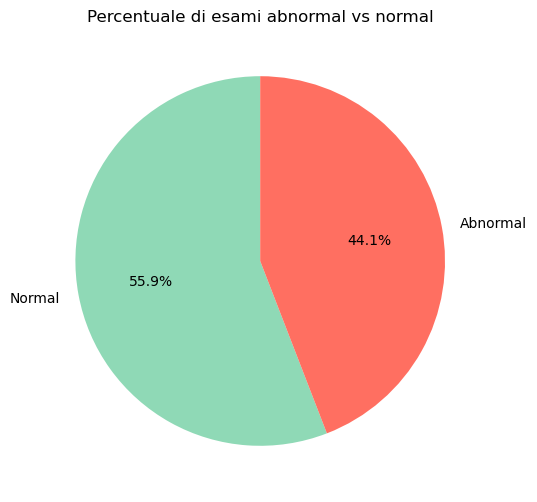

In [321]:
counts = modified['flag'].value_counts()

# Grafico a torta
plt.figure(figsize=(6,6))
plt.pie(
    counts,
    labels=['Normal', 'Abnormal'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#8fd9b6','#ff6f61']
)
plt.title("Percentuale di esami abnormal vs normal")
plt.show()

In [322]:
print(data_frame['label'].nunique())   

84


In [323]:
# Raggruppa per esame e calcola min e max
# Calcola min e max osservati per ogni esame
exam_min_max = (
    modified.groupby('label')['valuenum']
    .agg(['min', 'max'])
    .reset_index()
)

# Prendi i valori di riferimento (assumendo che siano già nel dataframe)
ref_ranges = (
   modified[['label', 'ref_range_lower', 'ref_range_upper','valueuom']]
    .drop_duplicates('label')   # evita duplicati per ogni eesame
)

# Unisci le due tabelle
exam_min_max = exam_min_max.merge(ref_ranges, on='label', how='left')

print(exam_min_max)


                        label    min      max  ref_range_lower  \
0     Absolute Basophil Count   0.00     0.66             0.01   
1   Absolute Eosinophil Count   0.00     1.50             0.04   
2   Absolute Lymphocyte Count   0.00  3825.00             1.20   
3     Absolute Monocyte Count   0.00     3.11             0.20   
4   Absolute Neutrophil Count   0.32    41.66             1.60   
..                        ...    ...      ...              ...   
76                  WBC Count   2.00    12.40             4.00   
77          White Blood Cells   0.40   234.90             4.00   
78                       pCO2  10.00   144.00            35.00   
79                         pH   6.94     7.70             7.35   
80                        pO2  17.00   549.00            85.00   

    ref_range_upper valueuom  
0              0.08     K/uL  
1              0.54     K/uL  
2              3.70     K/uL  
3              0.80     K/uL  
4              6.10     K/uL  
..              ...  

### le correlazione dopo mi servono per capire quali feature mettere nel profilo

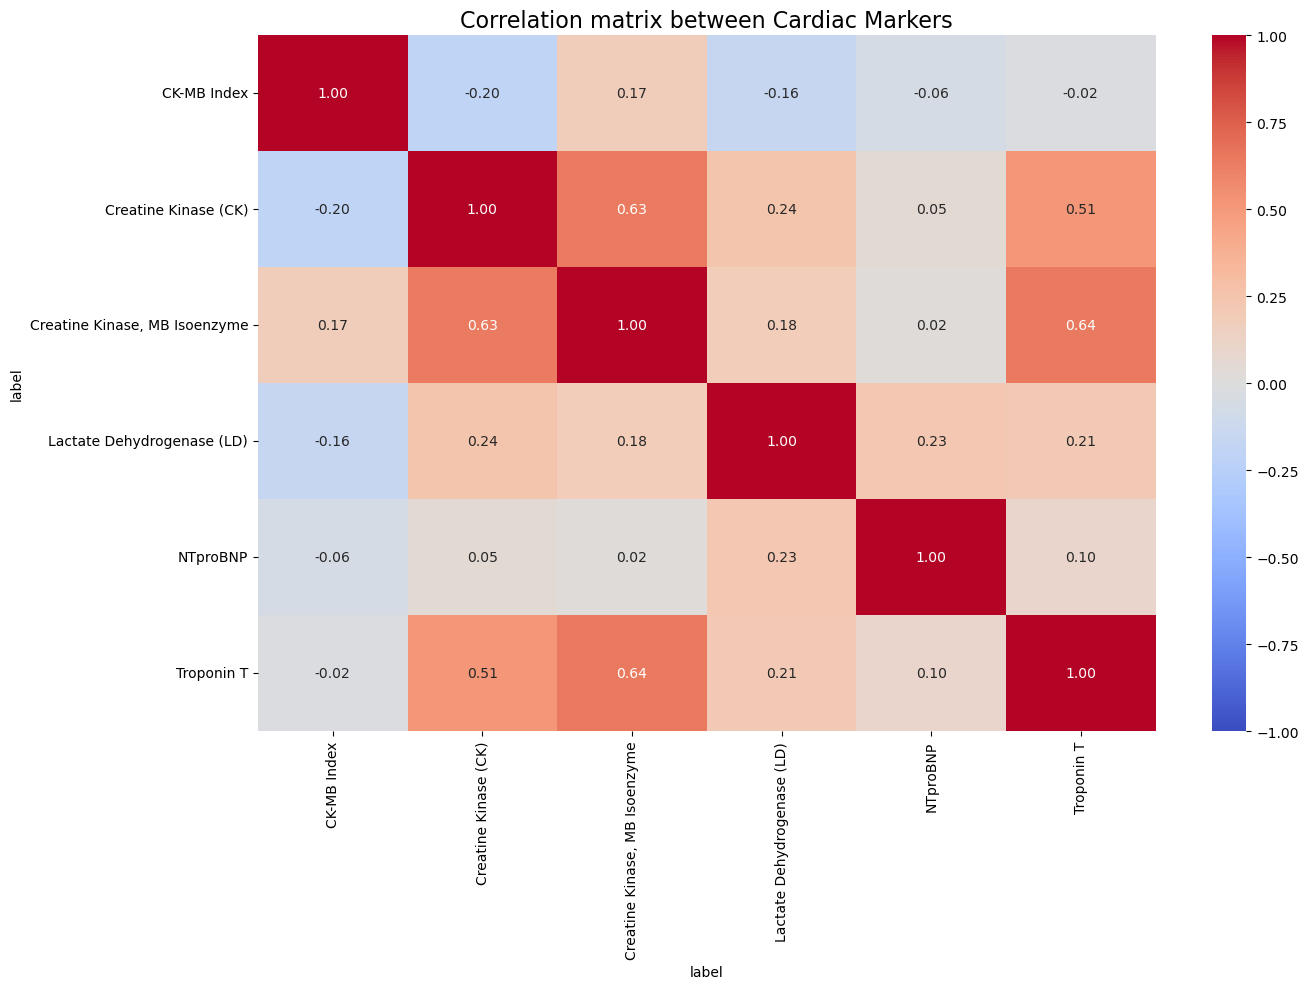

In [324]:
# Select data for Cardiac Markers examination group
subset = modified[modified['examination_group'] == 'Cardiac Markers']

# Pivot the data: each label becomes a column with valuenum as values
# Use subject_id and hadm_id to identify unique patient-admission combinations
pivot_data = subset.pivot_table(
    index=[ 'hadm_id'],
    columns='label',
    values='valuenum',
    aggfunc='mean'  # If multiple values exist, take the mean
)

# Calculate correlation matrix
corr_matrix = pivot_data.corr()

# Plot the heatmap
plt.figure(figsize=(14,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix between Cardiac Markers", fontsize=16)
plt.tight_layout()
plt.show()




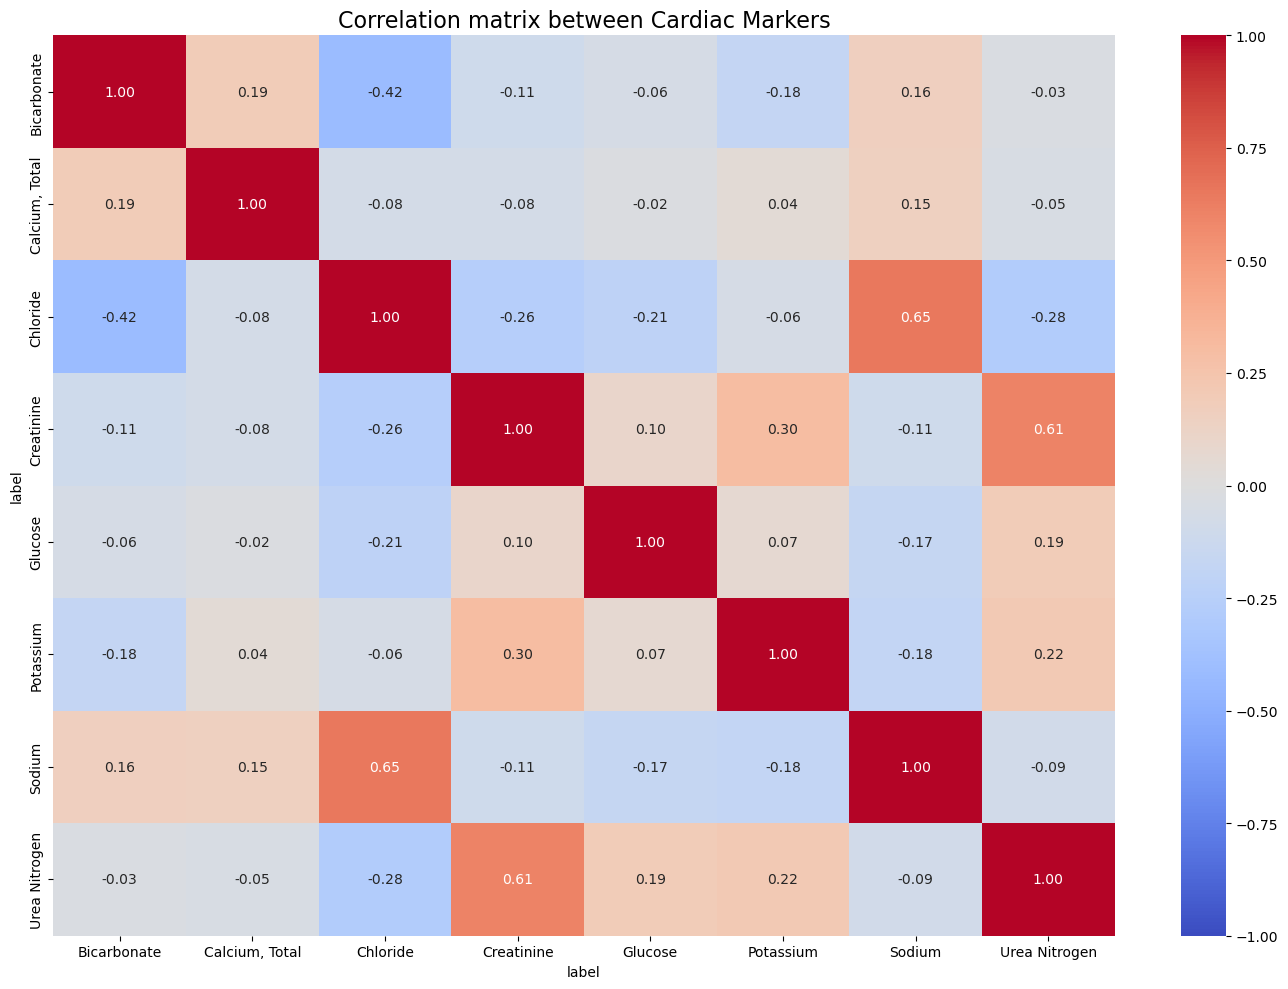

In [325]:
# Select data for Cardiac Markers examination group
subset = modified[modified['examination_group'] == 'BMP']

# Pivot the data: each label becomes a column with valuenum as values
# Use subject_id and hadm_id to identify unique patient-admission combinations
pivot_data = subset.pivot_table(
    index=[ 'hadm_id'],
    columns='label',
    values='valuenum',
    aggfunc='mean'  # If multiple values exist, take the mean
)

# Calculate correlation matrix
corr_matrix = pivot_data.corr()

# Plot the heatmap
plt.figure(figsize=(14,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix between Cardiac Markers", fontsize=16)
plt.tight_layout()
plt.show()




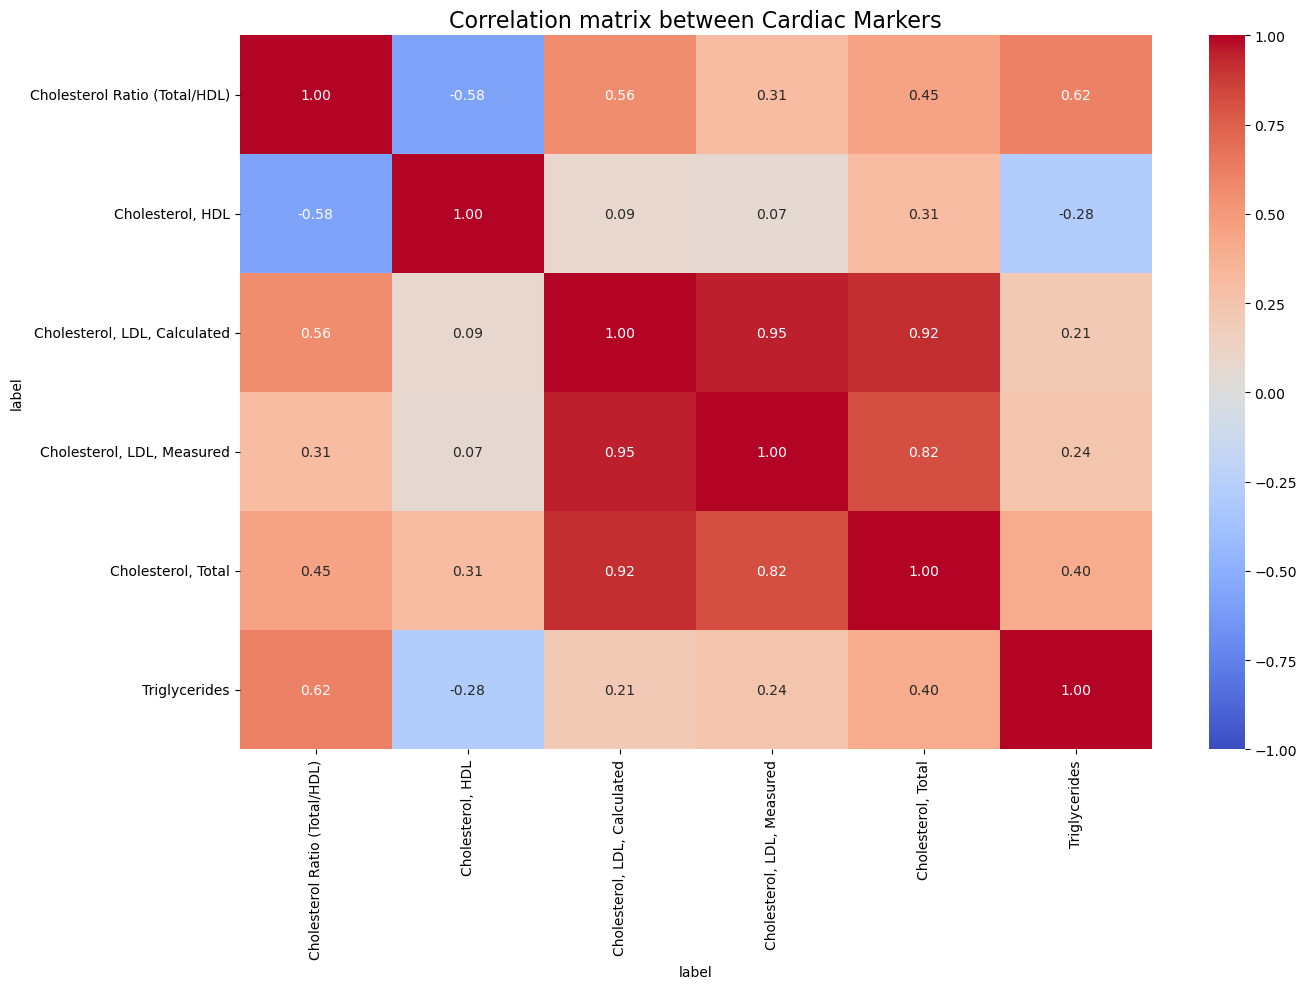

In [326]:
# Select data for Cardiac Markers examination group
subset = modified[modified['examination_group'] == 'Lipid Panel']

# Pivot the data: each label becomes a column with valuenum as values
# Use subject_id and hadm_id to identify unique patient-admission combinations
pivot_data = subset.pivot_table(
    index=[ 'hadm_id'],
    columns='label',
    values='valuenum',
    aggfunc='mean'  # If multiple values exist, take the mean
)

# Calculate correlation matrix
corr_matrix = pivot_data.corr()

# Plot the heatmap
plt.figure(figsize=(14,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix between Cardiac Markers", fontsize=16)
plt.tight_layout()
plt.show()




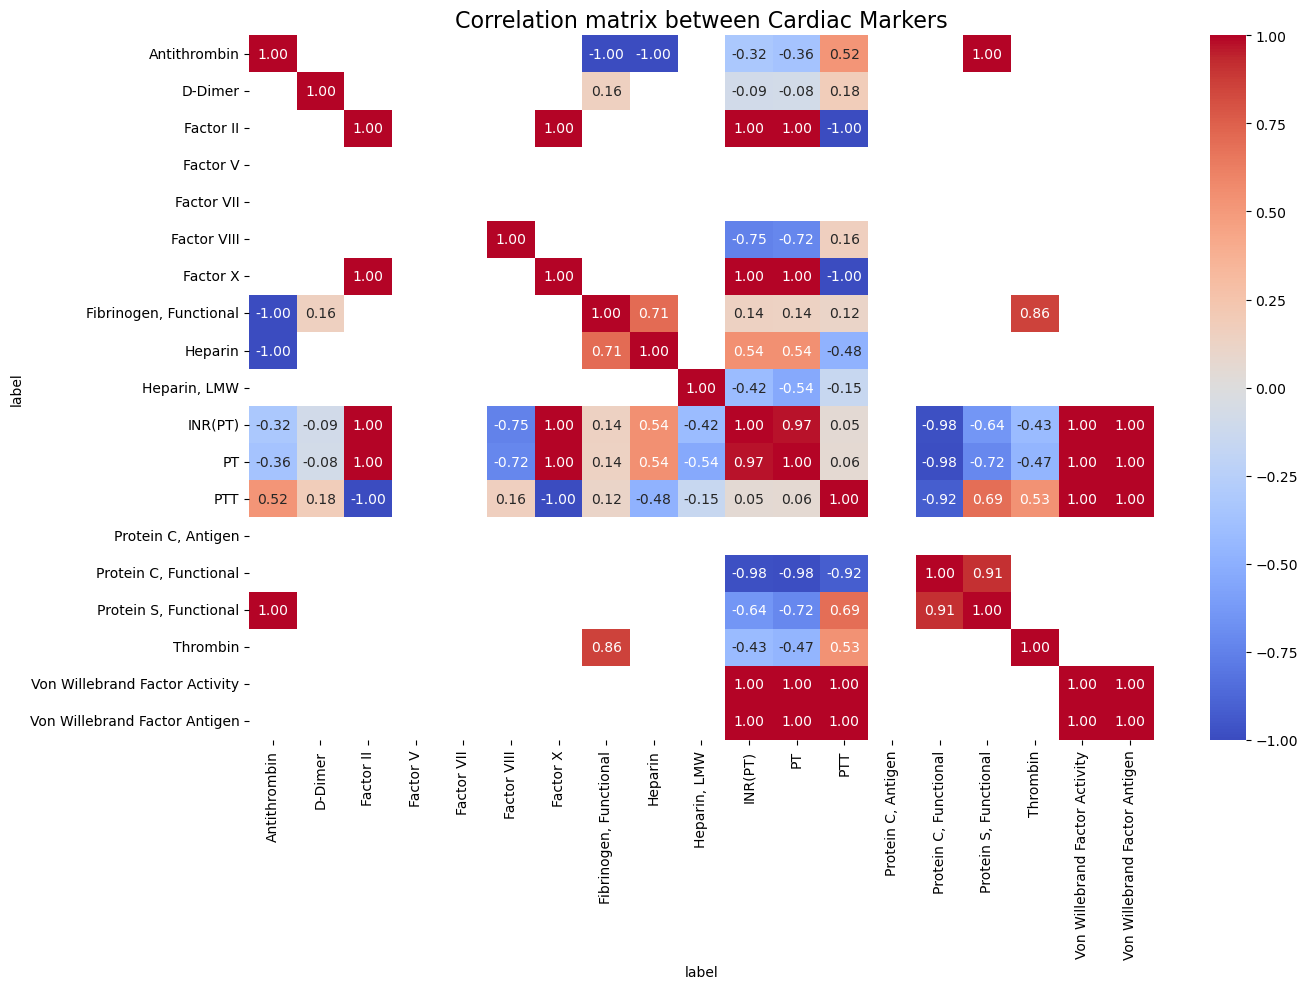

In [327]:
# Select data for Cardiac Markers examination group
subset = modified[modified['examination_group'] == 'Coagulation and Hemostasis']

# Pivot the data: each label becomes a column with valuenum as values
# Use subject_id and hadm_id to identify unique patient-admission combinations
pivot_data = subset.pivot_table(
    index=[ 'hadm_id'],
    columns='label',
    values='valuenum',
    aggfunc='mean'  # If multiple values exist, take the mean
)

# Calculate correlation matrix
corr_matrix = pivot_data.corr()

# Plot the heatmap
plt.figure(figsize=(14,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix between Cardiac Markers", fontsize=16)
plt.tight_layout()
plt.show()




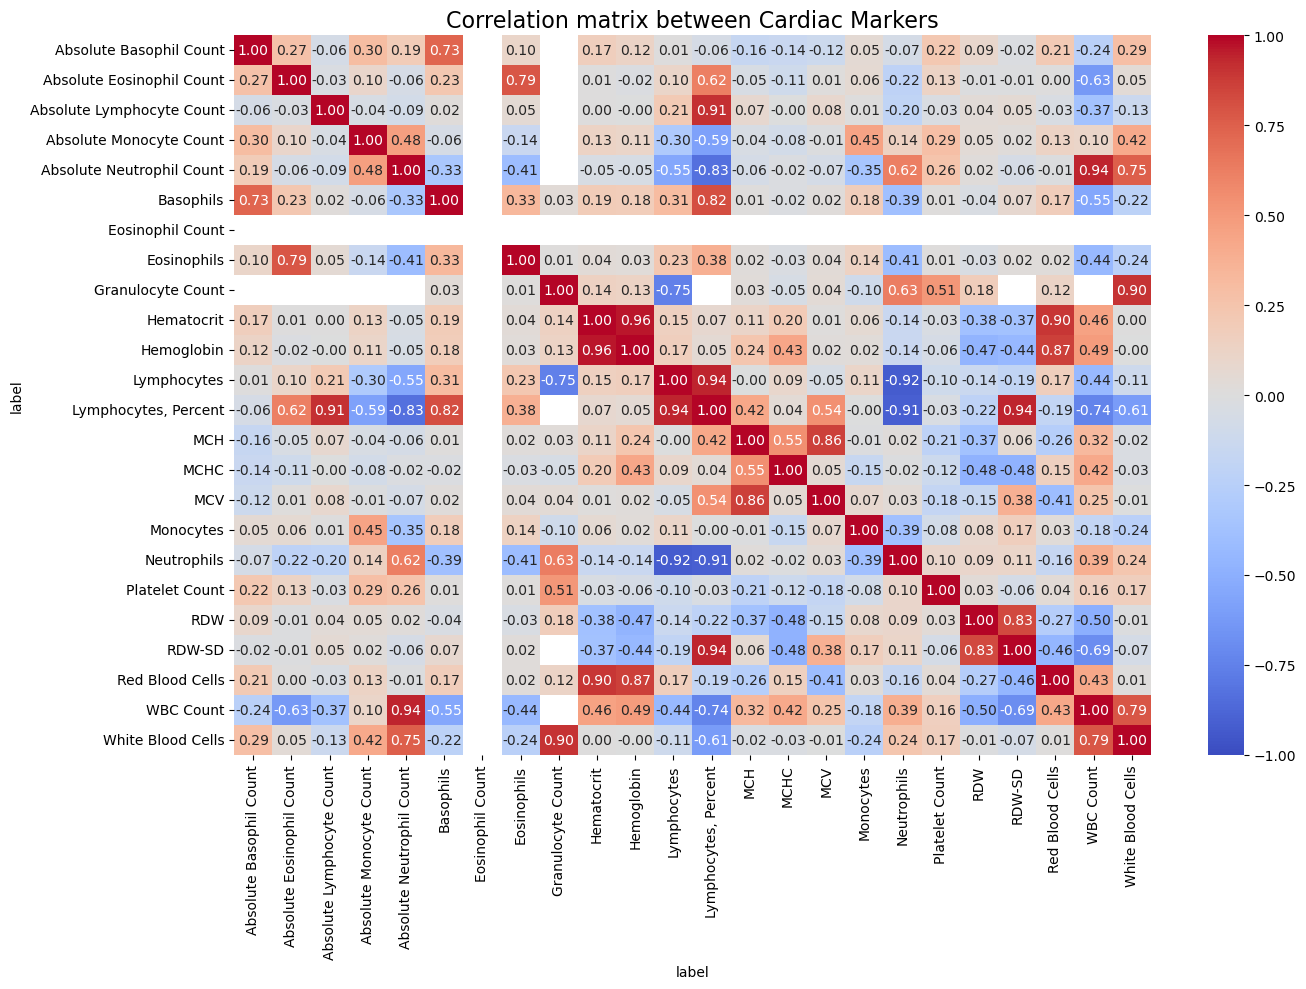

In [328]:
# Select data for Cardiac Markers examination group
subset = modified[modified['examination_group'] == 'Complete Blood Count (CBC)']

# Pivot the data: each label becomes a column with valuenum as values
# Use subject_id and hadm_id to identify unique patient-admission combinations
pivot_data = subset.pivot_table(
    index=[ 'hadm_id'],
    columns='label',
    values='valuenum',
    aggfunc='mean'  # If multiple values exist, take the mean
)

# Calculate correlation matrix
corr_matrix = pivot_data.corr()

# Plot the heatmap
plt.figure(figsize=(14,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix between Cardiac Markers", fontsize=16)
plt.tight_layout()
plt.show()




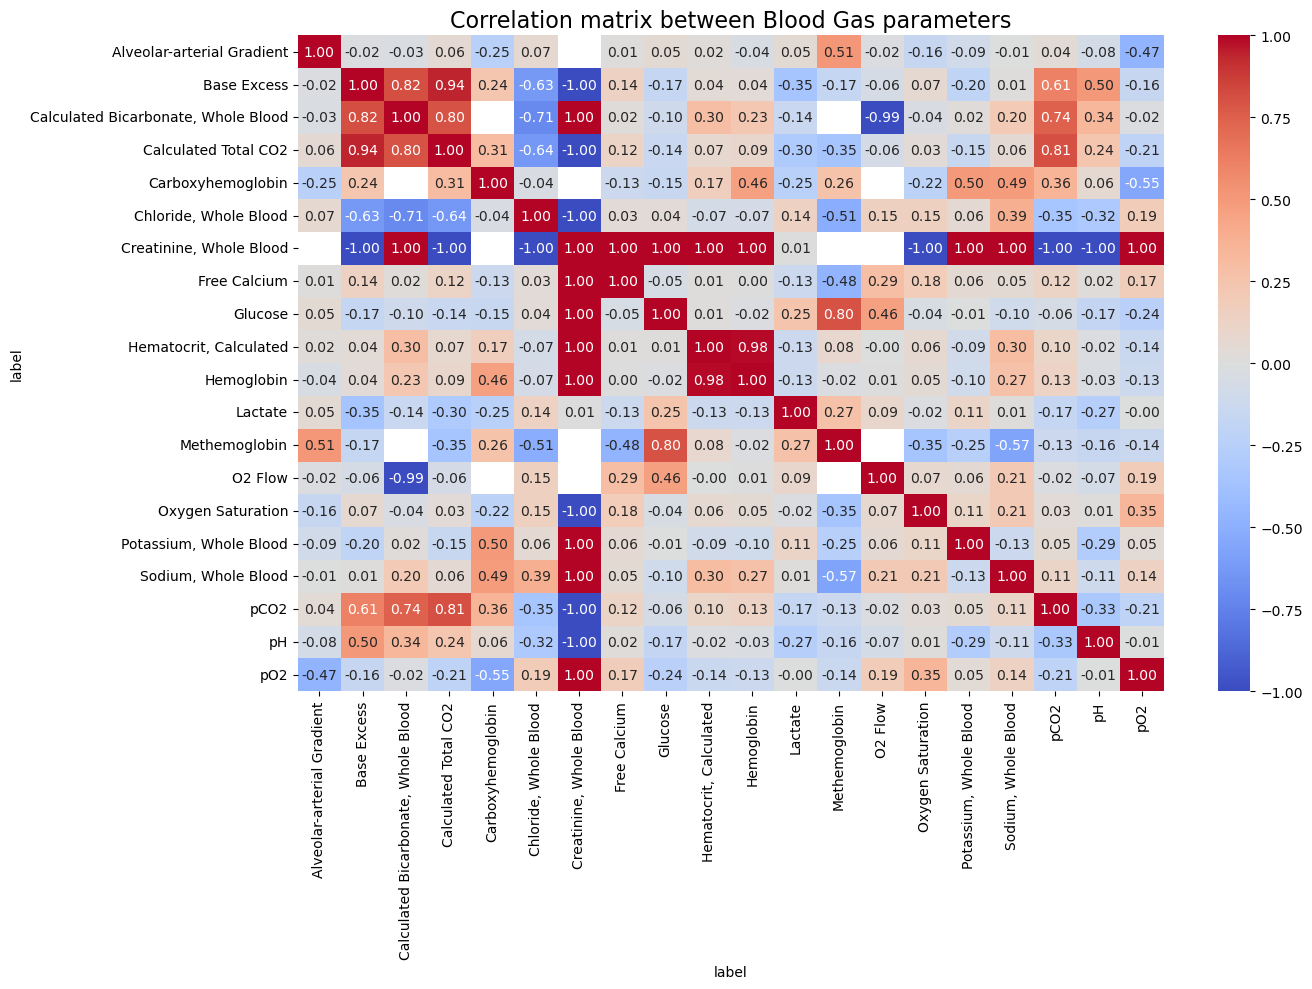

In [329]:
# correlation matrix for Blood Gas examination group
subset = modified[modified['examination_group'] == 'Blood Gas']
# Pivot the data: each label becomes a column with valuenum as values
# Use subject_id and hadm_id to identify unique patient-admission combinations
pivot_data = subset.pivot_table(
    index=[ 'hadm_id'],
    columns='label',
    values='valuenum',
    aggfunc='mean'  # If multiple values exist, take the mean
)
# Calculate correlation matrix
corr_matrix = pivot_data.corr()

# Plot the heatmap
plt.figure(figsize=(14,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix between Blood Gas parameters", fontsize=16)
plt.tight_layout()
plt.show()


### osservando i dati direi che sono tutti plausibili (trovare dare qualche esempio)

In [330]:
# Raggruppa per esame e calcola min e max
# Calcola min e max osservati per ogni esame
exam_min_max = (
    modified.groupby('label')['valuenum']
    .agg(['min', 'max'])
    .reset_index()
)

# Prendi i valori di riferimento (assumendo che siano già nel dataframe)
ref_ranges = (
   modified[['label', 'ref_range_lower', 'ref_range_upper','valueuom']]
    .drop_duplicates('label')   # evita duplicati per ogni eesame
)

# Unisci le due tabelle
exam_min_max = exam_min_max.merge(ref_ranges, on='label', how='left')

print(exam_min_max)



                        label    min      max  ref_range_lower  \
0     Absolute Basophil Count   0.00     0.66             0.01   
1   Absolute Eosinophil Count   0.00     1.50             0.04   
2   Absolute Lymphocyte Count   0.00  3825.00             1.20   
3     Absolute Monocyte Count   0.00     3.11             0.20   
4   Absolute Neutrophil Count   0.32    41.66             1.60   
..                        ...    ...      ...              ...   
76                  WBC Count   2.00    12.40             4.00   
77          White Blood Cells   0.40   234.90             4.00   
78                       pCO2  10.00   144.00            35.00   
79                         pH   6.94     7.70             7.35   
80                        pO2  17.00   549.00            85.00   

    ref_range_upper valueuom  
0              0.08     K/uL  
1              0.54     K/uL  
2              3.70     K/uL  
3              0.80     K/uL  
4              6.10     K/uL  
..              ...  

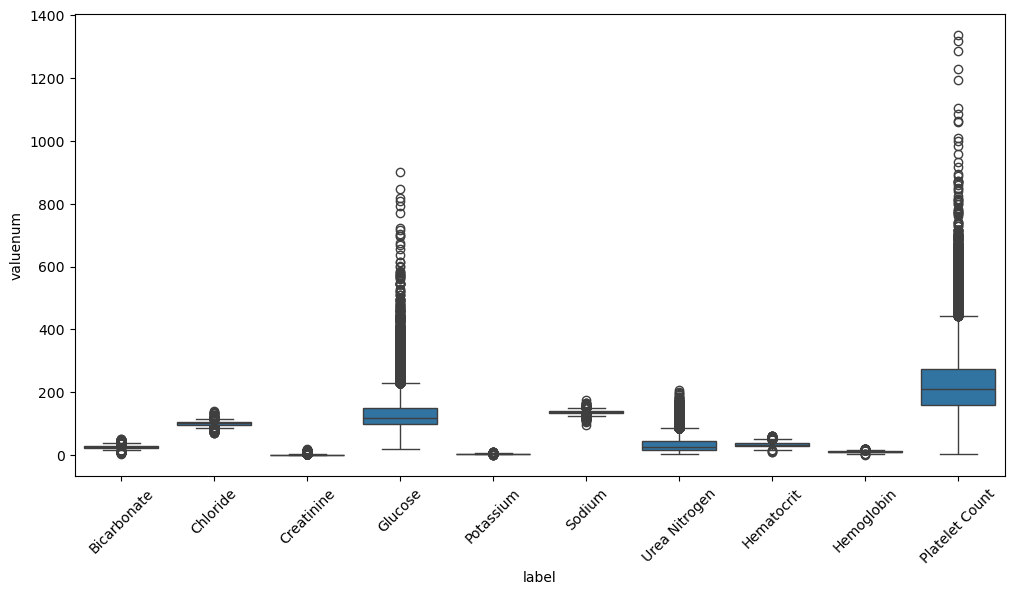

In [331]:
# Filtra solo gli esami sul fluido sangue


# Conta quante osservazioni per ogni esame
counts = modified['label'].value_counts().head(10).index

# Filtra solo i top 10 esami
subset = modified[modified['label'].isin(counts)]

plt.figure(figsize=(12,6))
sns.boxplot(x='label', y='valuenum', data=subset)
plt.xticks(rotation=45)
plt.show()
#modified.drop(['ref_range_lower', 'ref_range_upper'], axis=1, inplace=True)
modified.to_csv("../../data/processed/lab_events.csv", index=False)

In [ ]:
# Remove rows where valuenum is missing
modified = modified.dropna(subset=['valuenum'])

Righe totali: 654624 — valuenum vuoti/NaN: 0
Dropped 0 righe — nuova shape: (654624, 11)


In [335]:
#controllo di non aver perso altri pazienti
#merge con heart_diagnoses_df per avere subject_id
final_merge = pd.merge(modified, heart_diagnoses_df[['hadm_id', 'subject_id']], on='hadm_id', how='inner')
final_unique_patients = final_merge['subject_id'].nunique()

print(f"Pazienti unici finali: {final_unique_patients}")
modified

Pazienti unici finali: 4384


,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4
3,29654838.0,2188-01-05 06:56:00,1.20,u,0.9,1.10,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7
4,29654838.0,2188-01-05 06:56:00,85.80,sec,25.0,36.50,1,PTT,Blood,Coagulation and Hemostasis,BATCH_218801_R1
...,...,...,...,...,...,...,...,...,...,...,...
654619,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1
654620,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5
654621,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7
654622,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6
